# Cardiac MRI concept profiles — SAX and LAX

Restore the trained **ACDC central SAX** and **M&Ms-2 four-chamber LAX** stacked ED/ES ResNet50 models. Inspect the original images, extract final convolutional activations, identify cardiac concepts with Network Dissection, and visualize feature/concept importance for each image and target class.

Run from this repository with its Python dependencies and CineMA installed. The saved `architecture.json` supplies evaluation preprocessing; models use restored weights and evaluation mode throughout.

## 1. Paths and image selection

Defaults use the relocated sibling `Data and models` directory, with the SCAG results root as a fallback. Existing environment overrides remain available. `CLASS_NAME` selects the image's ground-truth class; `TARGET_CLASS=None` explains its predicted class, or set a class name such as `"HCM"`. Each view has its own class order and concept calibration.


In [1]:
import json
import os
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from omegaconf import OmegaConf

PROJECT_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "scag/config.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from within the SCAG repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cinema.classification.dataset import get_image_transforms
from scag.activations import extract_activations
from scag.config import SCAGConfig
from scag.data import ACDCSemanticDataset, MNMS2SemanticDataset, _get_acdc_eval_transform, _load_acdc_splits, _load_mnms2_splits, _validate_splits, phase_encode_segments
from scag.models import EDES2DClassifier
from scag.semantics import compute_neuron_concept_matrix

SHARED_ROOT = PROJECT_ROOT.parent / "Data and models"
SAX_CFG = SCAGConfig(dataset="acdc")
LAX_CFG = SCAGConfig(dataset="mnms2")
DATA_BASE = SHARED_ROOT / "datasets" if (SHARED_ROOT / "datasets").is_dir() else SAX_CFG.results_root / "processed"
MODEL_BASE = SHARED_ROOT / "model checkpoints/2d" if (SHARED_ROOT / "model checkpoints/2d").is_dir() else SAX_CFG.results_root / "architecture_bank/2d"
SAX_DATA_ROOT = Path(os.environ.get("ACDC_PROCESSED_DIR", DATA_BASE / "acdc")).expanduser().resolve()
LAX_DATA_ROOT = Path(os.environ.get("MNMS2_PROCESSED_DIR", DATA_BASE / "mnms2")).expanduser().resolve()
SAX_CHECKPOINT = Path(os.environ.get("ACDC_CHECKPOINT", MODEL_BASE / "acdc_sax_mid_2d/resnet50/stacked/imagenet/seed_0/best_val_mcc.pt")).expanduser().resolve()
LAX_CHECKPOINT = Path(os.environ.get("MNMS2_LAX_CHECKPOINT", MODEL_BASE / "mnms2_lax_4c/resnet50/stacked/imagenet/seed_0/best_val_mcc.pt")).expanduser().resolve()
OUTPUT_ROOT = PROJECT_ROOT / "outputs/concept_profiles"
DEVICE = SAX_CFG.device
SPLIT = "train"  # Choose train, val, or test for displayed images.
SAX_CLASS_NAME = "HCM"  # None includes every class.
LAX_CLASS_NAME = "HCM"
SAX_N_SAMPLES = 4
LAX_N_SAMPLES = 4
SAX_TARGET_CLASS = None  # None explains each image's predicted class.
LAX_TARGET_CLASS = None
BATCH_SIZE = 4
ACTIVATION_TAIL = SAX_CFG.alpha  # Top 0.5% of calibration activations.
IOU_THRESHOLD = SAX_CFG.eta  # Shared SCAG detector cutoff: 0.015.
CONCEPT_NAMES = SAX_CFG.concept_names[1:]
PROFILE_NAMES = (*CONCEPT_NAMES, "Unassigned")
# Concept order and colors match the supplied reference figure.
CONCEPT_COLORS = {
    "LV_ED": "#ff6666", "LV_ES": "#b93645",
    "RV_ED": "#6c8ebf", "RV_ES": "#315485",
    "MYO_ED": "#f4c84d", "MYO_ES": "#b38715",
}

print("Device:", DEVICE)
print("SAX:", SAX_DATA_ROOT, SAX_CHECKPOINT)
print("LAX:", LAX_DATA_ROOT, LAX_CHECKPOINT)


Device: cpu
SAX: /media/kislay/New Volume/Turab/0. Code workspace/Data and models/datasets/acdc /media/kislay/New Volume/Turab/0. Code workspace/Data and models/model checkpoints/2d/acdc_sax_mid_2d/resnet50/stacked/imagenet/seed_0/best_val_mcc.pt
LAX: /media/kislay/New Volume/Turab/0. Code workspace/Data and models/datasets/mnms2 /media/kislay/New Volume/Turab/0. Code workspace/Data and models/model checkpoints/2d/mnms2_lax_4c/resnet50/stacked/imagenet/seed_0/best_val_mcc.pt


## 2. Restore models and load images/masks

The same central SAX slice or LAX-4C plane is used for each image and its segmentation, with identical end padding. Segmentation labels are RV=1, myocardium=2, LV=3. Only evaluation transforms are applied, including to the calibration images from the training split.


acdc: restored resnet50; train=90, val=10, test=50
mnms2: restored resnet50; train=160, val=30, test=110


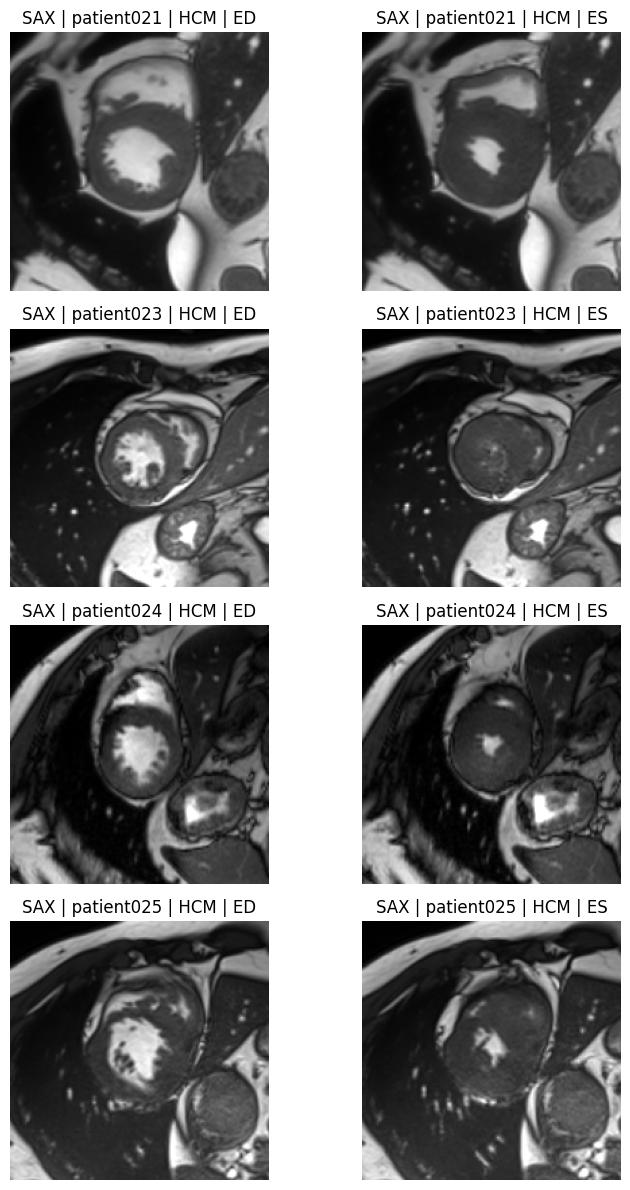

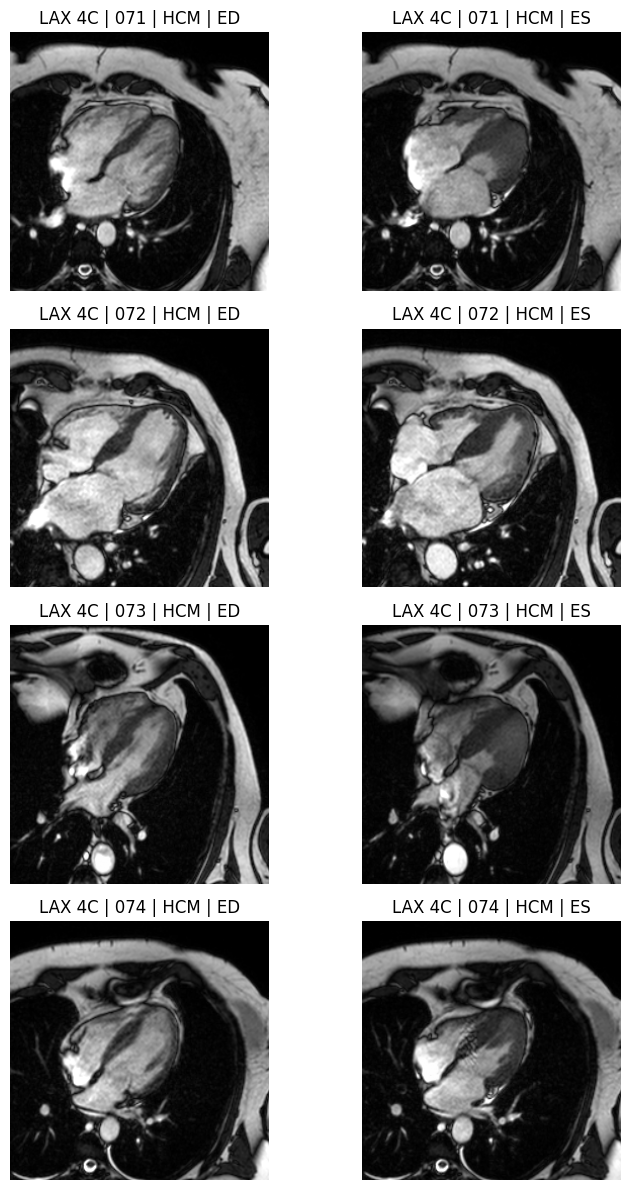

In [2]:
def load_view(cfg, data_root, checkpoint_path):
    architecture_path = checkpoint_path.parent / "architecture.json"
    for path in (checkpoint_path, architecture_path):
        if not path.is_file():
            raise FileNotFoundError(path)
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    architecture = json.loads(architecture_path.read_text())
    for key, expected in {"task": cfg.task_name, "classes": list(cfg.classes), "formulation": "stacked"}.items():
        if checkpoint.get(key) != expected or architecture.get(key) != expected:
            raise ValueError(f"Checkpoint/architecture {key} must match {expected!r}.")
    for key in ("backbone", "initialization"):
        if checkpoint[key] != architecture[key]:
            raise ValueError(f"Checkpoint and architecture disagree on {key}.")
    if not checkpoint["backbone"].startswith("resnet"):
        raise ValueError("Exact feature contributions require a stacked ResNet with a linear classifier.")
    model = EDES2DClassifier(checkpoint["backbone"], "stacked", "randinit", len(cfg.classes))
    model.load_state_dict(checkpoint["model"], strict=True)
    model.initialization = checkpoint["initialization"]
    model = model.to(DEVICE).eval()
    config = OmegaConf.create(architecture["config"])
    config.data.dir = str(data_root)
    if config.model.views != cfg.view or tuple(config.data[config.data.class_column]) != cfg.classes:
        raise ValueError("Saved preprocessing view/class order does not match the checkpoint.")
    adapter = SimpleNamespace(data_root=data_root, classes=cfg.classes, view=cfg.view)
    if cfg.dataset == "acdc":
        splits = _load_acdc_splits(adapter)
        transform = _get_acdc_eval_transform(config)
        datasets = {split: ACDCSemanticDataset(split, frame, transform, adapter) for split, frame in splits.items()}
    else:
        splits = _load_mnms2_splits(adapter)
        _, transform = get_image_transforms(config)
        datasets = {split: MNMS2SemanticDataset(split, frame, transform, adapter, config) for split, frame in splits.items()}
    _validate_splits(splits, cfg)
    print(f"{cfg.dataset}: restored {checkpoint['backbone']}; " + ", ".join(f"{split}={len(ds)}" for split, ds in datasets.items()))
    return model, model.encoder.layer4, datasets


def select_images(datasets, split, class_name, n_samples):
    if split not in datasets:
        raise ValueError(f"Unknown split: {split!r}")
    if type(n_samples) is not int or n_samples < 1:
        raise ValueError("n_samples must be a positive integer.")
    dataset = datasets[split]
    metadata = dataset.metadata
    if class_name is not None:
        class_name = class_name.strip().upper()
        if class_name not in set(metadata["pathology"]):
            raise ValueError(f"No {class_name!r} images in {split}.")
        metadata = metadata[metadata["pathology"] == class_name]
    indices = metadata.index[:n_samples].tolist()
    if not indices:
        raise ValueError("No images selected.")
    return [dataset[index] for index in indices]


sax_model, sax_layer, sax_datasets = load_view(SAX_CFG, SAX_DATA_ROOT, SAX_CHECKPOINT)
lax_model, lax_layer, lax_datasets = load_view(LAX_CFG, LAX_DATA_ROOT, LAX_CHECKPOINT)
sax_samples = select_images(sax_datasets, SPLIT, SAX_CLASS_NAME, SAX_N_SAMPLES)
lax_samples = select_images(lax_datasets, SPLIT, LAX_CLASS_NAME, LAX_N_SAMPLES)

for view, samples in (("SAX", sax_samples), ("LAX 4C", lax_samples)):
    fig, axes = plt.subplots(len(samples), 2, figsize=(8, 3 * len(samples)), squeeze=False)
    for row, (image, mask, info) in enumerate(samples):
        for phase_index, phase in enumerate(("ED", "ES")):
            axes[row, phase_index].imshow(image[phase_index], cmap="gray", vmin=0, vmax=1)
            axes[row, phase_index].set_title(f"{view} | {info['pid']} | {info['pathology']} | {phase}")
            axes[row, phase_index].axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)


## 3. Extract activations and dissect cardiac concepts

Reuse the repository's [Network Dissection](https://openaccess.thecvf.com/content_cvpr_2017/html/Bau_Network_Dissection_Quantifying_CVPR_2017_paper.html) procedure: estimate a per-channel upper-tail threshold over **all training-split images**, upsample each activation map, then measure dataset-wide intersection-over-union (IoU) against phase-encoded masks. The resulting `X` is a **channel × concept** matrix for RV, MYO and LV at ED and ES. `IOU_THRESHOLD` uses this project's cutoff; adjust it to change detector eligibility.

SAX and LAX are dissected separately. This fits semantic associations without updating model weights. The stacked ED/ES network produces joint spatial activations; phase labels describe mask associations, not separate phase-specific forward passes. Full-resolution dissection may take a few minutes on CPU.


In [3]:
def dissect_view(model, layer, calibration_dataset):
    if not 0 < ACTIVATION_TAIL < 1 or not 0 < IOU_THRESHOLD <= 1:
        raise ValueError("Require 0 < ACTIVATION_TAIL < 1 and 0 < IOU_THRESHOLD <= 1.")
    loader = torch.utils.data.DataLoader(calibration_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    activations, masks = extract_activations(model, loader, layer, DEVICE)
    if masks is None or masks.shape[1] != 2 or not torch.all((masks >= 0) & (masks <= 3)):
        raise ValueError("Dissection requires aligned ED/ES masks with labels 0, 1, 2, 3.")
    X, labeled = compute_neuron_concept_matrix(activations, phase_encode_segments(masks), 7, ACTIVATION_TAIL, IOU_THRESHOLD)
    # A channel with no response cannot be a semantic detector, even when its threshold is zero.
    active = activations.amax(dim=(0, 2, 3)).numpy() > 0
    X[~active] = 0
    labeled &= active
    print(f"Activations: {tuple(activations.shape)}; labeled channels: {labeled.sum()}/{len(labeled)}")
    return X, labeled


sax_X, sax_labeled = dissect_view(sax_model, sax_layer, sax_datasets["train"])
lax_X, lax_labeled = dissect_view(lax_model, lax_layer, lax_datasets["train"])

detector_counts = pd.DataFrame({"concept": CONCEPT_NAMES, "SAX detectors": (sax_X[:, 1:] >= IOU_THRESHOLD).sum(axis=0), "LAX detectors": (lax_X[:, 1:] >= IOU_THRESHOLD).sum(axis=0)})
print(detector_counts.to_string(index=False))


  dissect 128/2048
  dissect 256/2048
  dissect 384/2048
  dissect 512/2048
  dissect 640/2048
  dissect 768/2048
  dissect 896/2048
  dissect 1024/2048
  dissect 1152/2048
  dissect 1280/2048
  dissect 1408/2048
  dissect 1536/2048
  dissect 1664/2048
  dissect 1792/2048
  dissect 1920/2048
  dissect 2048/2048
Activations: (90, 2048, 6, 6); labeled channels: 902/2048
  dissect 128/2048
  dissect 256/2048
  dissect 384/2048
  dissect 512/2048
  dissect 640/2048
  dissect 768/2048
  dissect 896/2048
  dissect 1024/2048
  dissect 1152/2048
  dissect 1280/2048
  dissect 1408/2048
  dissect 1536/2048
  dissect 1664/2048
  dissect 1792/2048
  dissect 1920/2048
  dissect 2048/2048
Activations: (160, 2048, 8, 8); labeled channels: 831/2048
concept  SAX detectors  LAX detectors
  RV_ED             29            193
 MYO_ED            106            172
  LV_ED            704            654
  RV_ES             37            201
 MYO_ES            316            410
  LV_ES            576       

## 4. Image/class concept profiles

For final-layer channel `k` and class `c`, **feature contribution = spatial mean activation[k] × classifier weight[c,k]**. For these stacked ResNets, feature contributions plus the classifier bias exactly reconstruct the class logit; no gradients are needed.

For semantic display, normalize eligible IoUs within each labeled channel and distribute its contribution among the six concepts. IoUs below the detector cutoff are excluded. Unlabeled channels go into **Unassigned**, preserving the full score. This semantic allocation is an interpretation of channel associations, rather than a causal effect of an anatomical region. Positive values support the target logit and negative values oppose it; values are logit units, not probabilities. The classifier bias is reported separately.


In [4]:
def concept_allocation(X, labeled, iou_threshold=IOU_THRESHOLD):
    X = np.asarray(X, dtype=np.float32)
    labeled = np.asarray(labeled, dtype=bool)
    if X.ndim != 2 or X.shape[1] != 7 or labeled.shape != (len(X),):
        raise ValueError("Expected channel × 7 IoUs and one detector flag per channel.")
    if not np.isfinite(X).all() or np.any((X < 0) | (X > 1)):
        raise ValueError("IoUs must be finite and between zero and one.")
    association = np.where(labeled[:, None] & (X[:, 1:] >= iou_threshold), X[:, 1:], 0)
    totals = association.sum(axis=1, keepdims=True)
    association = np.divide(association, totals, out=np.zeros_like(association), where=totals > 0)
    return np.column_stack((association, (totals[:, 0] == 0).astype(np.float32)))


def image_profiles(model, layer, samples, X, labeled, classes, target_class=None):
    if target_class is not None and target_class.strip().upper() not in classes:
        raise ValueError(f"Target class must be one of {classes}.")
    loader = torch.utils.data.DataLoader(samples, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    activations, _ = extract_activations(model, loader, layer, DEVICE)
    pooled = activations.mean(dim=(2, 3)).numpy()
    weight = model.classifier.weight.detach().cpu().numpy()
    bias = model.classifier.bias.detach().cpu().numpy()
    feature_scores = pooled[:, None, :] * weight[None, :, :]
    logits = feature_scores.sum(axis=2) + bias
    with torch.no_grad():
        actual_logits = torch.cat([model(batch[0].to(DEVICE)).cpu() for batch in loader]).numpy()
    np.testing.assert_allclose(logits, actual_logits, rtol=1e-4, atol=1e-4)
    allocation = concept_allocation(X, labeled)
    profiles = feature_scores @ allocation
    np.testing.assert_allclose(profiles.sum(axis=2) + bias, logits, rtol=1e-4, atol=1e-4)
    predictions = logits.argmax(axis=1)
    targets = predictions if target_class is None else np.full(len(samples), classes.index(target_class.strip().upper()))
    probabilities = torch.from_numpy(logits).softmax(dim=1).numpy()
    rows = []
    for index, (_, _, info) in enumerate(samples):
        target = int(targets[index])
        rows.append({
            "pid": info["pid"], "image_class": info["pathology"], "predicted_class": classes[predictions[index]],
            "target_class": classes[target], "target_probability": float(probabilities[index, target]),
            "target_logit": float(logits[index, target]), "classifier_bias": float(bias[target]),
            **dict(zip(PROFILE_NAMES, profiles[index, target].tolist())),
        })
    return {"activations": activations, "feature_scores": feature_scores, "profiles": profiles, "targets": targets, "classifier_bias": bias, "logits": logits, "probabilities": probabilities, "table": pd.DataFrame(rows)}


# Runnable arithmetic check: mixed concepts, negative evidence and unassigned channels conserve the score.
check_X = np.zeros((3, 7), dtype=np.float32)
check_X[0, 1], check_X[0, 2], check_X[1, 3] = 0.1, 0.3, 0.2
check_allocation = concept_allocation(check_X, np.array([True, True, False]), iou_threshold=0.015)
np.testing.assert_allclose(check_allocation.sum(axis=1), 1)
check_scores = np.array([4., -2., 3.]) @ check_allocation
np.testing.assert_allclose(check_scores, [1, 3, -2, 0, 0, 0, 3])
assert np.isclose(check_scores.sum(), 5)
assert np.all(concept_allocation(check_X, np.zeros(3, dtype=bool))[:, -1] == 1)
print("Concept allocation self-check passed.")


Concept allocation self-check passed.


## 5. Stacked concept profiles — percentages and raw strengths

Compare **ACDC SAX** and **M&Ms-2 LAX** side by side, with one horizontal stacked bar per patient and target class. Colors and concept order match the supplied reference: LV ED/ES in red, RV ED/ES in blue, and myocardium ED/ES in yellow.

**Percentage:** `100 × abs(concept contribution) / sum(abs(six named concept contributions))`. Each nonzero row sums to 100%; these are shares of named concept strength, not prediction probabilities or neuron counts. Zero-strength rows are shown explicitly. **Raw:** signed contributions in logit units, with supporting concepts stacked to the right and opposing concepts to the left of zero. Classifier bias remains separate.

Figures show only the six named concepts. Residual contributions remain in the raw CSV/NPZ and are excluded from the stacks and percentage denominator. Patient IDs and target classes are actual model outputs; the rows do not represent graph communities.

Each patient also gets an image/profile figure: the ED and ES images sit side by side above one joint stacked profile, with translucent ground-truth RV, myocardium, and LV masks and outlines. Each phase uses exactly the same colors as its profile concepts; background is transparent. Percentage and raw versions are saved separately, using the same concept colors.

Use the normalized percentage figure for comparing relative concept composition across images. Keep the raw signed figure alongside it to retain absolute strength and distinguish supporting from opposing evidence; percentage magnitudes discard signs and total strength. Anatomical overlays show dataset annotations, while the profile shows model channel contributions associated with those concepts.


ACDC · SAX raw image/class profiles:
       pid image_class predicted_class target_class  target_probability  target_logit  classifier_bias   RV_ED  MYO_ED   LV_ED   RV_ES  MYO_ES   LV_ES
patient021         HCM             HCM          HCM              0.9275        3.0974           0.0028 -0.0050  0.2538  0.5002 -0.0063  1.1768  0.0377
patient023         HCM             HCM          HCM              0.8722        2.4549           0.0028 -0.0005  0.2224  0.3098 -0.0092  0.9174 -0.0077
patient024         HCM             HCM          HCM              0.9568        3.6564           0.0028 -0.0082  0.3282  0.6568 -0.0038  1.4083  0.0687
patient025         HCM             NOR          NOR              0.5176        1.1135           0.0092  0.0078  0.0028 -0.0502  0.0211 -0.0181 -0.1630
M&Ms-2 · LAX 4C raw image/class profiles:
pid image_class predicted_class target_class  target_probability  target_logit  classifier_bias  RV_ED  MYO_ED  LV_ED  RV_ES  MYO_ES  LV_ES
071         HCM           

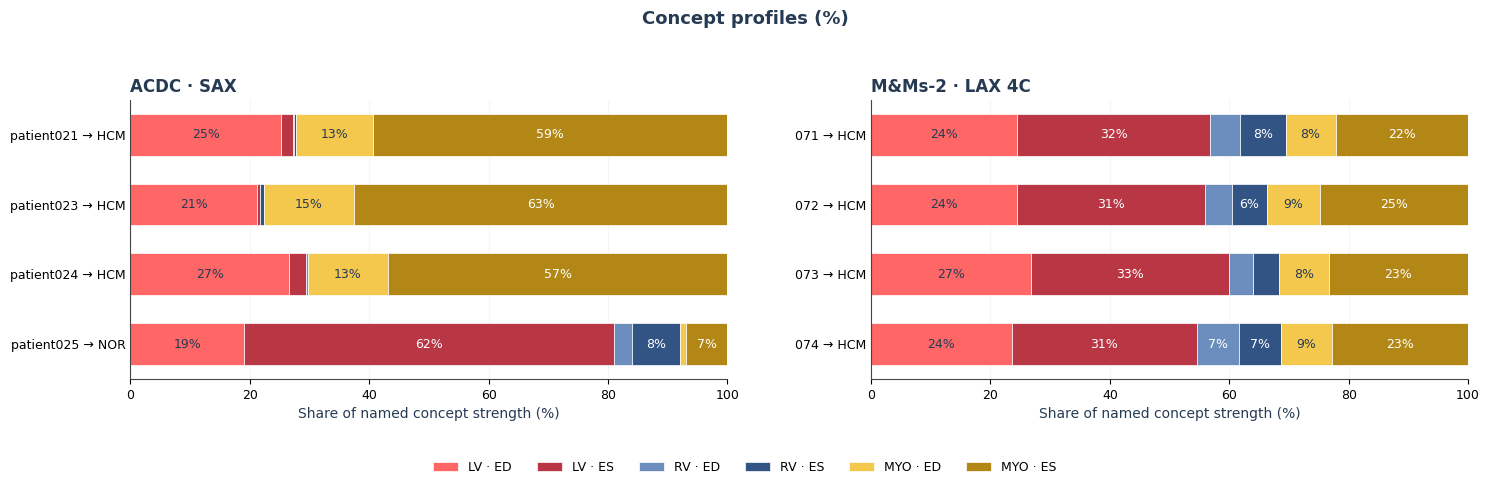

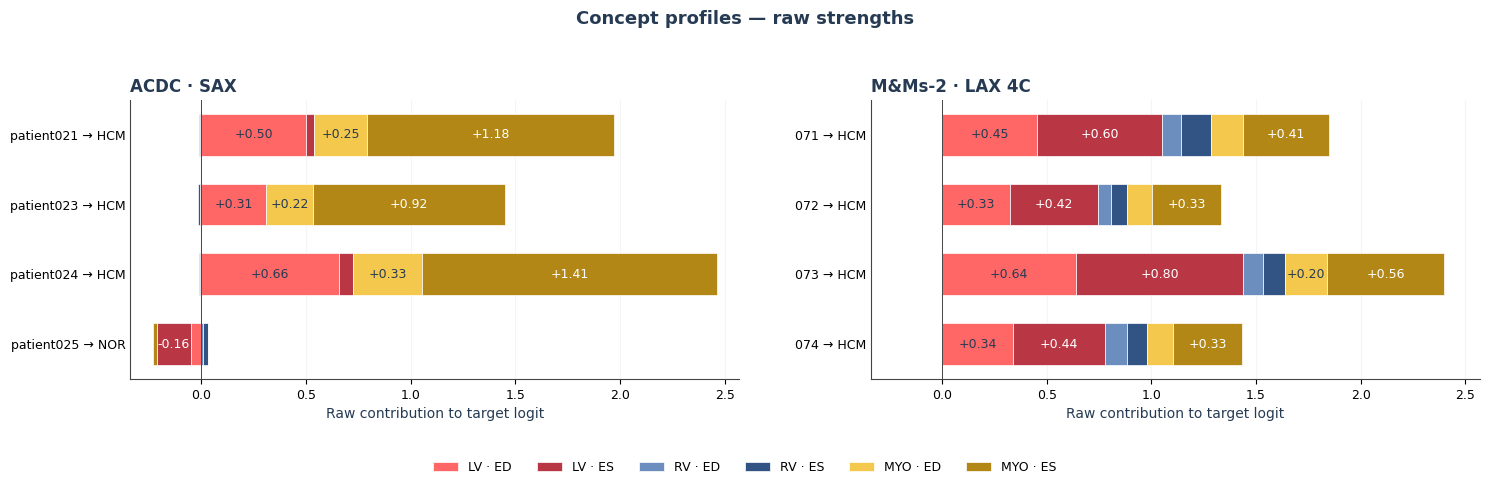

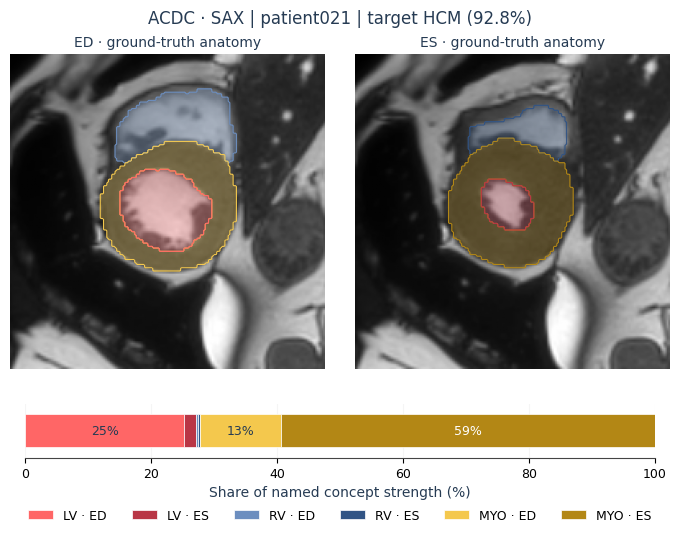

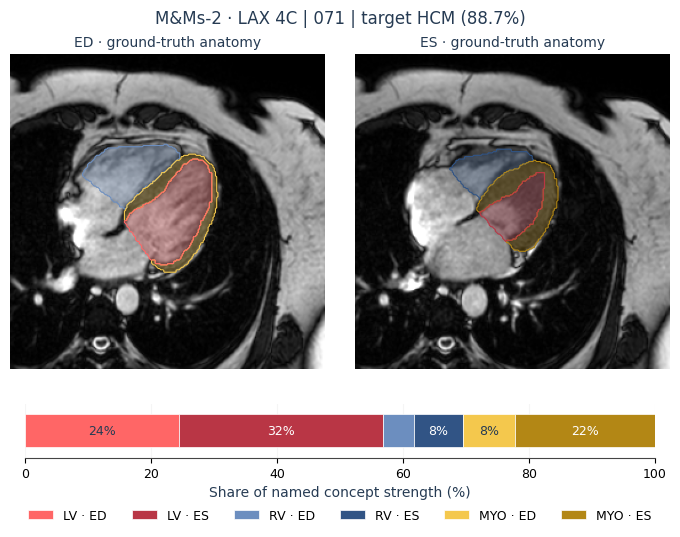

In [5]:
def profile_values(table, percentage=False):
    values = table[list(CONCEPT_COLORS)].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Concept contributions must be finite.")
    if percentage:
        values = np.abs(values)
        totals = values.sum(axis=1, keepdims=True)
        values = np.divide(100 * values, totals, out=np.zeros_like(values), where=totals > 0)
    return values


def plot_profiles(panels, percentage=False):
    values = [profile_values(result["table"], percentage) for _, result in panels]
    height = max(len(result["table"]) for _, result in panels)
    fig, axes = plt.subplots(1, len(panels), figsize=(7.5 * len(panels), max(3.8, 0.8 * height + 1.7)), squeeze=False)
    positive_limit = max(float(np.maximum(value, 0).sum(axis=1).max()) for value in values)
    negative_limit = max(float(-np.minimum(value, 0).sum(axis=1).min()) for value in values)
    span = max(positive_limit + negative_limit, 0.01)
    for ax, (view, result), value in zip(axes.flat, panels, values):
        table = result["table"]
        positions = np.arange(len(table))
        positive, negative = np.zeros(len(table)), np.zeros(len(table))
        for index, (name, color) in enumerate(CONCEPT_COLORS.items()):
            widths = value[:, index]
            left = np.where(widths >= 0, positive, negative)
            ax.barh(positions, widths, left=left, height=0.6, color=color, edgecolor="white", linewidth=0.5, label=name.replace("_", " · "))
            for row, width in enumerate(widths):
                if abs(width) >= (5 if percentage else 0.06 * span):
                    label = f"{width:.0f}%" if percentage else f"{width:+.2f}"
                    text_color = "#263b53" if name in ("LV_ED", "MYO_ED") else "white"
                    ax.text(left[row] + width / 2, row, label, ha="center", va="center", fontsize=9, color=text_color)
            positive += np.maximum(widths, 0)
            negative += np.minimum(widths, 0)
        labels = [f"{record.pid} → {record.target_class}" for record in table.itertuples()]
        ax.set_yticks(positions, labels, fontsize=9)
        ax.set_ylim(len(table) - 0.5, -0.5)
        ax.set_xlim((0, 100) if percentage else (-negative_limit - 0.04 * span if negative_limit > 0 else 0, positive_limit + 0.04 * span))
        ax.set_xlabel("Share of named concept strength (%)" if percentage else "Raw contribution to target logit", fontsize=10, color="#263b53")
        ax.set_title(view, loc="left", fontweight="bold", fontsize=12, color="#263b53")
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines["left"].set_color("#444444")
        ax.spines["bottom"].set_color("#444444")
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=9)
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.12)
        if not percentage:
            ax.axvline(0, color="#444444", linewidth=0.7)
        for row in np.flatnonzero(np.abs(value).sum(axis=1) == 0):
            ax.text(0.02, row, "No named concept strength", transform=ax.get_yaxis_transform(), va="center", fontsize=9, color="#666666")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0.01))
    fig.suptitle("Concept profiles (%)" if percentage else "Concept profiles — raw strengths", fontsize=13, fontweight="bold", color="#263b53")
    fig.tight_layout(rect=(0, 0.11, 1, 0.94), w_pad=4)
    return fig


def plot_anatomy(ax, image, mask, phase):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    colors = [CONCEPT_COLORS[f"{anatomy}_{phase}"] for anatomy in ("RV", "MYO", "LV")]
    ax.imshow(np.ma.masked_equal(mask, 0), cmap=ListedColormap(["none", *colors]), vmin=0, vmax=3, alpha=0.28, interpolation="nearest")
    for label, color in enumerate(colors, start=1):
        region = mask == label
        if region.any() and not region.all():
            ax.contour(region, levels=[0.5], colors=[color], linewidths=0.8)
    ax.axis("off")


def plot_image_profile(sample, result, index, view, percentage=False):
    image, mask, info = sample
    mask = np.asarray(mask)
    if mask.shape != tuple(image.shape) or not np.isin(mask, [0, 1, 2, 3]).all():
        raise ValueError("Anatomical masks must match ED/ES images and use labels 0, 1, 2, 3.")
    record = result["table"].iloc[index]
    if str(info["pid"]) != str(record["pid"]):
        raise ValueError("Image and concept profile patient IDs do not match.")
    fig = plot_profiles([(view, {"table": result["table"].iloc[[index]]})], percentage=percentage)
    fig.set_size_inches(7.5, 5.4)
    profile_ax = fig.axes[0]
    profile_ax.set_position([0.08, 0.15, 0.84, 0.10])
    profile_ax.set_yticks([])
    profile_ax.set_title("", loc="left")
    profile_ax.locator_params(axis="x", nbins=6)
    profile_ax.spines["left"].set_visible(False)
    for phase_index, phase in enumerate(("ED", "ES")):
        ax = fig.add_axes([0.06 + 0.46 * phase_index, 0.30, 0.42, 0.61])
        plot_anatomy(ax, image[phase_index], mask[phase_index], phase)
        ax.set_title(f"{phase} · ground-truth anatomy", fontsize=10, color="#263b53")
    fig.suptitle(f"{view} | {info['pid']} | target {record['target_class']} ({record['target_probability']:.1%})", fontsize=12, color="#263b53")
    return fig


# Percentage normalization must handle mixed signs and zero-strength images.
check_table = pd.DataFrame([[2, -1, 1, 0, 0, 0], [0, 0, 0, 0, 0, 0]], columns=list(CONCEPT_COLORS))
np.testing.assert_allclose(profile_values(check_table, percentage=True), [[50, 25, 25, 0, 0, 0], [0, 0, 0, 0, 0, 0]])
np.testing.assert_allclose(profile_values(check_table), check_table.to_numpy())

# Overlay check: background stays transparent and RV/MYO/LV use the correct phase colors.
check_sample = (torch.zeros(2, 2, 2), torch.tensor([[[0, 1], [2, 3]], [[0, 1], [2, 3]]]), {"pid": "mask-check"})
check_result = {"table": pd.DataFrame([{**dict.fromkeys(CONCEPT_COLORS, 0.), "pid": "mask-check", "target_class": "HCM", "target_probability": 0.5}])}
check_figure = plot_image_profile(check_sample, check_result, 0, "Mask check", percentage=True)
for phase, ax in zip(("ED", "ES"), check_figure.axes[1:]):
    overlay = ax.images[1]
    assert np.ma.getmaskarray(overlay.get_array())[0, 0]
    np.testing.assert_allclose(overlay.cmap(np.arange(4))[1:, :3], [to_rgb(CONCEPT_COLORS[f"{anatomy}_{phase}"]) for anatomy in ("RV", "MYO", "LV")])
plt.close(check_figure)

sax_result = image_profiles(sax_model, sax_layer, sax_samples, sax_X, sax_labeled, SAX_CFG.classes, SAX_TARGET_CLASS)
lax_result = image_profiles(lax_model, lax_layer, lax_samples, lax_X, lax_labeled, LAX_CFG.classes, LAX_TARGET_CLASS)
comparison_panels = [("ACDC · SAX", sax_result), ("M&Ms-2 · LAX 4C", lax_result)]
for view, result in comparison_panels:
    print(view + " raw image/class profiles:")
    print(result["table"].drop(columns="Unassigned").round(4).to_string(index=False))
for percentage in (True, False):
    fig = plot_profiles(comparison_panels, percentage=percentage)
    plt.show()
    plt.close(fig)

for view, samples, result in (("ACDC · SAX", sax_samples, sax_result), ("M&Ms-2 · LAX 4C", lax_samples, lax_result)):
    fig = plot_image_profile(samples[0], result, 0, view, percentage=True)
    plt.show()
    plt.close(fig)


## 6. See what each concept detector activates on

For the first selected image in each view, display the channel with the highest eligible IoU for each concept. These are **individual forward activation maps**, with the corresponding ground-truth anatomy outlined in cyan. Each map has its own intensity scale. An absent eligible detector is shown explicitly. These joint ED/ES maps visualize association; they are not class contribution maps.


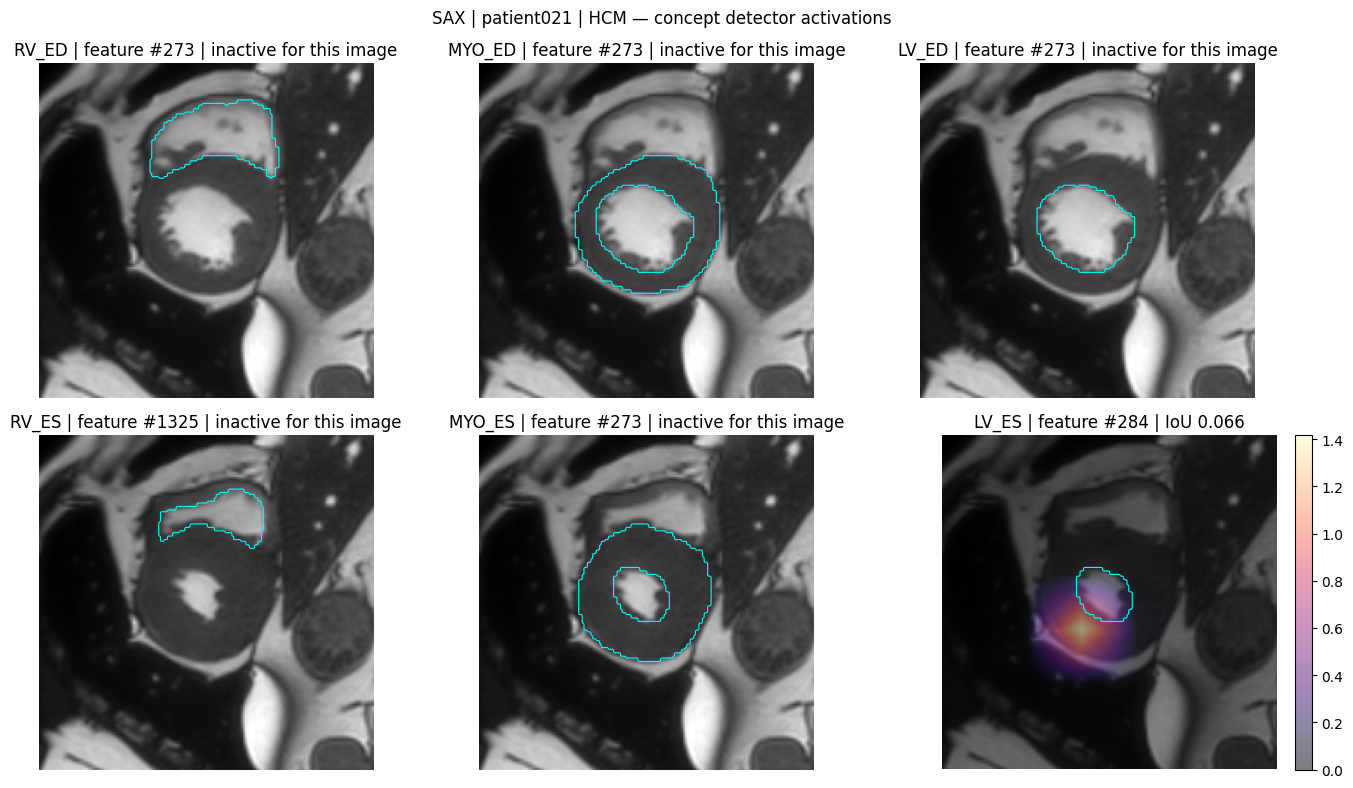

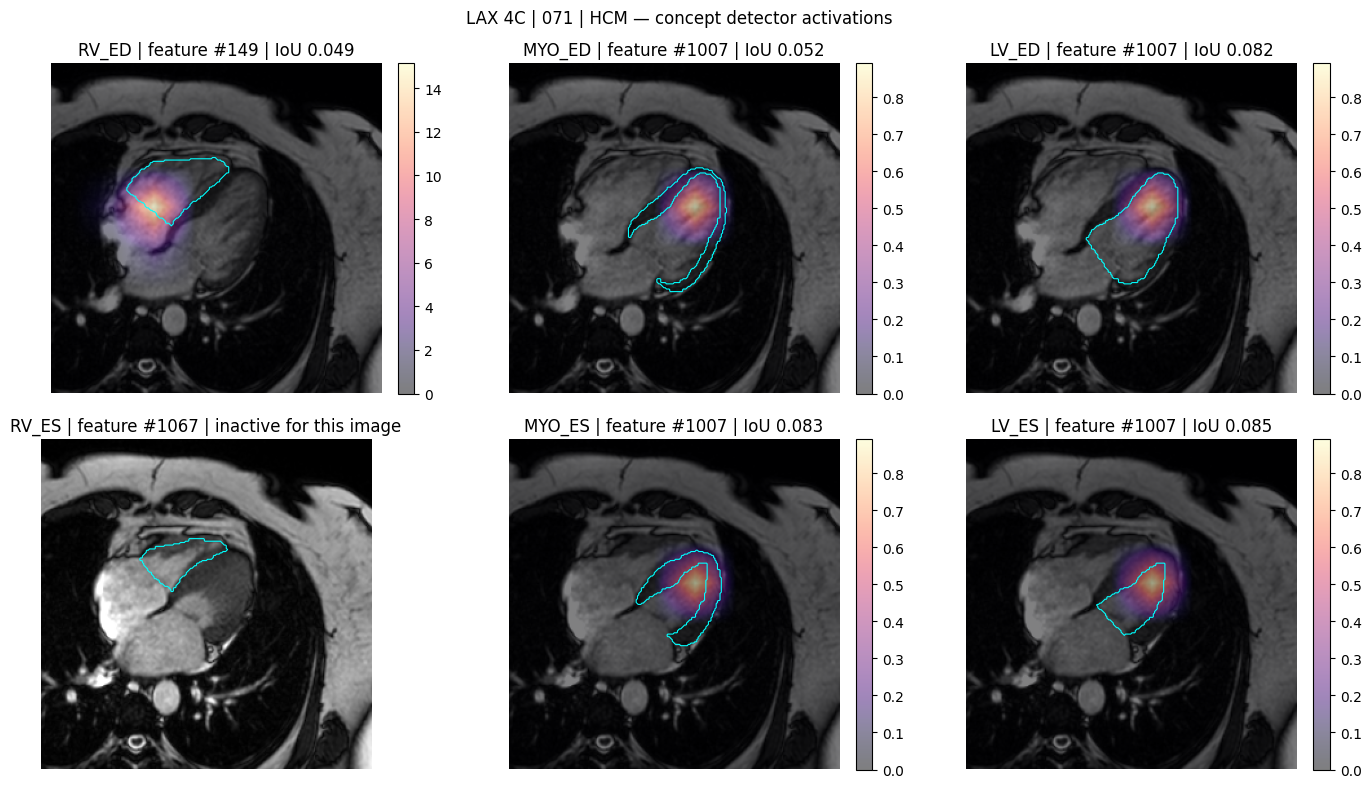

In [6]:
def plot_concept_activations(sample, activation, X, labeled, view):
    image, mask, info = sample
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for concept_index, (name, ax) in enumerate(zip(CONCEPT_NAMES, axes.flat), start=1):
        phase_index = (concept_index - 1) // 3
        anatomy_label = (concept_index - 1) % 3 + 1
        ax.imshow(image[phase_index], cmap="gray", vmin=0, vmax=1)
        candidates = np.flatnonzero(labeled & (X[:, concept_index] >= IOU_THRESHOLD))
        if len(candidates):
            channel = int(candidates[np.argmax(X[candidates, concept_index])])
            heatmap = F.interpolate(activation[channel][None, None], size=image.shape[-2:], mode="bilinear", align_corners=False)[0, 0].numpy()
            if heatmap.max() > 0:
                overlay = ax.imshow(heatmap, cmap="magma", alpha=0.5)
                fig.colorbar(overlay, ax=ax, fraction=0.046, pad=0.04)
                status = f"IoU {X[channel, concept_index]:.3f}"
            else:
                status = "inactive for this image"
            ax.set_title(f"{name} | feature #{channel} | {status}")
        else:
            ax.set_title(f"{name} | no eligible detector")
        region = mask[phase_index].numpy() == anatomy_label
        if region.any() and not region.all():
            ax.contour(region, levels=[0.5], colors=["cyan"], linewidths=0.8)
        ax.axis("off")
    fig.suptitle(f"{view} | {info['pid']} | {info['pathology']} — concept detector activations")
    fig.tight_layout()
    return fig


for view, samples, result, X, labeled in (("SAX", sax_samples, sax_result, sax_X, sax_labeled), ("LAX 4C", lax_samples, lax_result, lax_X, lax_labeled)):
    fig = plot_concept_activations(samples[0], result["activations"][0], X, labeled, view)
    plt.show()
    plt.close(fig)


## 7. Save organized exports

Exports are grouped by **view → split → ground-truth image diagnosis**. An HCM patient stays in the HCM folders even when its predicted/target class differs. Original images and anatomical mask overlays use matching `<pid>_ED.png` / `<pid>_ES.png` filenames.

```text
outputs/concept_profiles/
├── acdc_sax/train/
│   ├── original_HCM/         # original ED/ES images
│   ├── masks_HCM/            # separate anatomy overlays
│   ├── concept_HCM/
│   │   ├── percentage/       # <pid>.png: masked images + percentage profile
│   │   ├── raw/              # <pid>.png: masked images + raw signed profile
│   │   └── detector_activations.png
│   └── data/                 # CSV profiles + activation/concept/mask NPZ
├── mnms2_lax_4c/train/        # same structure
└── comparison/train/         # SAX/LAX comparison figures, PNG and SVG
```

Each concept subfolder also contains `profiles.png`, summarizing patients of that image class. Selecting multiple diagnoses creates `original_<CLASS>`, `masks_<CLASS>` and `concept_<CLASS>` folders for each class. `data/` retains all selected patients together, with patient IDs and diagnoses identifying each row. The NPZ includes original integer mask labels as well as activations and all-class scores.

Percentage CSV concept columns use percent units; the residual `Unassigned` column retains its raw signed logit contribution. `mean_profiles_by_image_class.csv` averages raw profiles over the displayed cohort for every possible target class and describes only these selected images.


In [7]:
def export_view(view, samples, result, X, labeled, classes, checkpoint_path):
    output_dir = OUTPUT_ROOT / view / SPLIT
    data_dir = output_dir / "data"
    data_dir.mkdir(parents=True, exist_ok=True)
    for image_class in sorted(result["table"]["image_class"].unique()):
        indices = np.flatnonzero(result["table"]["image_class"].to_numpy() == image_class)
        directories = {
            "original": output_dir / f"original_{image_class}",
            "masks": output_dir / f"masks_{image_class}",
            "concept": output_dir / f"concept_{image_class}",
        }
        for directory in directories.values():
            directory.mkdir(parents=True, exist_ok=True)
        for suffix in ("percentage", "raw"):
            (directories["concept"] / suffix).mkdir(parents=True, exist_ok=True)
        for index in indices:
            sample = samples[index]
            image, mask, info = sample
            for phase_index, phase in enumerate(("ED", "ES")):
                filename = f"{info['pid']}_{phase}.png"
                plt.imsave(directories["original"] / filename, image[phase_index].numpy(), cmap="gray", vmin=0, vmax=1)
                height, width = image.shape[-2:]
                fig, ax = plt.subplots(figsize=(width / 100, height / 100), dpi=100)
                plot_anatomy(ax, image[phase_index], mask[phase_index].numpy(), phase)
                fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
                fig.savefig(directories["masks"] / filename, dpi=100, pad_inches=0)
                plt.close(fig)
            for percentage, suffix in ((True, "percentage"), (False, "raw")):
                fig = plot_image_profile(sample, result, index, view, percentage=percentage)
                fig.savefig(directories["concept"] / suffix / f"{info['pid']}.png", dpi=180, bbox_inches="tight")
                plt.close(fig)
        class_result = {"table": result["table"].iloc[indices]}
        for percentage, suffix in ((True, "percentage"), (False, "raw")):
            fig = plot_profiles([(f"{view} · {image_class}", class_result)], percentage=percentage)
            fig.savefig(directories["concept"] / suffix / "profiles.png", dpi=150, bbox_inches="tight")
            plt.close(fig)
        index = int(indices[0])
        fig = plot_concept_activations(samples[index], result["activations"][index], X, labeled, view)
        fig.savefig(directories["concept"] / "detector_activations.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    percentage_table = result["table"][["pid", "image_class", "target_class", "Unassigned"]].copy()
    percentage_table[list(CONCEPT_COLORS)] = profile_values(result["table"], percentage=True)
    percentage_table.to_csv(data_dir / "image_concept_profiles_percentage.csv", index=False)
    result["table"].to_csv(data_dir / "image_concept_profiles.csv", index=False)
    image_classes = np.array([info["pathology"] for _, _, info in samples])
    summary = []
    for image_class in sorted(set(image_classes)):
        members = image_classes == image_class
        for class_index, target_class in enumerate(classes):
            scores = result["profiles"][members, class_index].mean(axis=0)
            summary.append({"image_class": image_class, "target_class": target_class, "n_images": int(members.sum()), **dict(zip(PROFILE_NAMES, scores.tolist()))})
    pd.DataFrame(summary).to_csv(data_dir / "mean_profiles_by_image_class.csv", index=False)
    np.savez_compressed(
        data_dir / "activations_and_concept_profiles.npz",
        activations=result["activations"].numpy(), X=X, labeled=labeled, allocation=concept_allocation(X, labeled),
        feature_scores=result["feature_scores"], concept_profiles=result["profiles"], target_indices=result["targets"],
        patient_ids=np.array([info["pid"] for _, _, info in samples]), image_classes=image_classes,
        classes=np.array(classes), concept_names=np.array(("background", *CONCEPT_NAMES)), profile_names=np.array(PROFILE_NAMES),
        classifier_bias=result["classifier_bias"], logits=result["logits"], probabilities=result["probabilities"], checkpoint=str(checkpoint_path),
        masks=np.stack([mask.numpy() for _, mask, _ in samples]),
        feature_layer="encoder.layer4", calibration_split="train", calibration_class_filter="all", activation_tail=ACTIVATION_TAIL, iou_threshold=IOU_THRESHOLD,
    )
    print("Saved", output_dir)


export_view("acdc_sax", sax_samples, sax_result, sax_X, sax_labeled, SAX_CFG.classes, SAX_CHECKPOINT)
export_view("mnms2_lax_4c", lax_samples, lax_result, lax_X, lax_labeled, LAX_CFG.classes, LAX_CHECKPOINT)

comparison_dir = OUTPUT_ROOT / "comparison" / SPLIT
comparison_dir.mkdir(parents=True, exist_ok=True)
for percentage, suffix in ((True, "percentage"), (False, "raw")):
    fig = plot_profiles(comparison_panels, percentage=percentage)
    for extension in ("png", "svg"):
        fig.savefig(comparison_dir / f"sax_lax_concept_profiles_{suffix}.{extension}", dpi=180, bbox_inches="tight")
    plt.close(fig)
print("Saved comparison figures", comparison_dir)

# Export check: originals and masks pair by patient/phase, and concepts follow the image diagnosis.
for view, samples in (("acdc_sax", sax_samples), ("mnms2_lax_4c", lax_samples)):
    directory = OUTPUT_ROOT / view / SPLIT
    for _, _, info in samples:
        for phase in ("ED", "ES"):
            filename = f"{info['pid']}_{phase}.png"
            assert (directory / f"original_{info['pathology']}" / filename).is_file()
            assert (directory / f"masks_{info['pathology']}" / filename).is_file()
        for suffix in ("percentage", "raw"):
            assert (directory / f"concept_{info['pathology']}" / suffix / f"{info['pid']}.png").is_file()


Saved /media/kislay/New Volume/Turab/0. Code workspace/1. global-analyisis-using-scag/outputs/concept_profiles/acdc_sax/train
Saved /media/kislay/New Volume/Turab/0. Code workspace/1. global-analyisis-using-scag/outputs/concept_profiles/mnms2_lax_4c/train
Saved comparison figures /media/kislay/New Volume/Turab/0. Code workspace/1. global-analyisis-using-scag/outputs/concept_profiles/comparison/train
